# 03 - Validasi Kanonikal Gold Set Sentimen Manusia

**Zahir Social Analytics — Ground Truth Sentimen Ulasan Google Play Store**

---

### Deskripsi & Metodologi Gold Set
Notebook ini memvalidasi dataset **Gold Set Sentimen Manusia** (`playstore_gold_set_final.csv`) yang berfungsi sebagai *ground truth* (kebenaran dasar) untuk seluruh evaluasi model pemrosesan bahasa alami (NLP) pada ekosistem Zahir.

Prinsip Utama Gold Set:
- **Anotasi Manual Manusia**: Seluruh 417 ulasan dianotasi secara manual oleh manusia berdasarkan pedoman anotasi linguistik terstandarisasi, **bukan hasil prediksi model machine learning** dan **bukan konversi otomatis dari skor rating**.
- **Distribusi Tiga Kelas**:
  - `positive`: 232 ulasan (55.64%)
  - `neutral`: 112 ulasan (26.86%)
  - `negative`: 73 ulasan (17.51%)
- **Immutabilitas Data**: Label Gold Set kanonikal berstatus beku (*immutable*) dan tidak boleh diubah oleh proses inferensi otomatis.

---

### Metadata Input & Output
- **File Input**:
  - `data/final/playstore_gold_set_final.csv` (Gold Set kanonikal: 417 baris, 4 kolom).
  - `data/final/playstore_reviews_final.csv` (Dataset ulasan terproses: 417 baris, 21 kolom).
- **Output Artefak**:
  - Output grafik: `outputs/figures/goldset_distribution.png`.
- **Prasyarat Lingkungan**:
  - Python 3.11.x, `pandas`, `matplotlib`, `seaborn`.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'export').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'data' / 'export').is_dir():
    raise FileNotFoundError('Jalankan Jupyter Notebook dari root repository atau folder notebooks.')

sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']

FIG_DIR = ROOT / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Root direktori: {ROOT}')
print('Setup library validasi Gold Set selesai.')


Root direktori: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics
Setup library validasi Gold Set selesai.


## 1. Pemuatan Data & Audit Keunikan Kunci Primer

Memuat dataset Gold Set dan dataset ulasan Play Store terproses, memverifikasi bahwa seluruh 417 ulasan terhubung 1-to-1 via `review_id` tanpa ada data yang hilang atau terduplikasi.


In [2]:
gold_path = ROOT / 'data' / 'final' / 'playstore_gold_set_final.csv'
review_path = ROOT / 'data' / 'final' / 'playstore_reviews_final.csv'

assert gold_path.is_file(), f'Gold Set tidak ditemukan: {gold_path}'
assert review_path.is_file(), f'Review final tidak ditemukan: {review_path}'

gold = pd.read_csv(gold_path)
reviews = pd.read_csv(review_path)

print(f'Gold Set Dimuat: {gold.shape[0]} baris, {gold.shape[1]} kolom.')
print(f'Reviews Dimuat: {reviews.shape[0]} baris, {reviews.shape[1]} kolom.')

# Validasi Keunikan & Kelengkapan
checks = {
    'Jumlah baris tepat 417': len(gold) == 417,
    'ID Gold Set unik & lengkap': gold['review_id'].notna().all() and gold['review_id'].is_unique,
    'ID Review unik & lengkap': reviews['review_id'].notna().all() and reviews['review_id'].is_unique,
    'Cakupan ID identik 100%': set(gold['review_id']) == set(reviews['review_id']),
    'Label sentimen valid (pos/neu/neg)': gold['human_sentiment_label'].isin(['positive', 'neutral', 'negative']).all(),
    'Tanpa missing label sentimen': gold['human_sentiment_label'].notna().all()
}

audit_summary = pd.DataFrame(list(checks.items()), columns=['Dimensi Pemeriksaan', 'Status'])
display(audit_summary)

assert all(checks.values()), 'Pemeriksaan integritas Gold Set gagal!'
print('[PASS] Integritas kunci primer dan kelengkapan label Gold Set terpenuhi 100%.')


Gold Set Dimuat: 417 baris, 7 kolom.
Reviews Dimuat: 417 baris, 21 kolom.


,Dimensi Pemeriksaan,Status
0,Jumlah baris tepat 417,True
1,ID Gold Set unik & lengkap,True
2,ID Review unik & lengkap,True
3,Cakupan ID identik 100%,True
4,Label sentimen valid (pos/neu/neg),True
5,Tanpa missing label sentimen,True


[PASS] Integritas kunci primer dan kelengkapan label Gold Set terpenuhi 100%.


## 2. Distribusi Sentimen Manusia & Perbandingan Terhadap Rating Bintang

### Distingsi Metodologi: Sentimen Teks vs Skor Rating
- **Rating (Skor 1 - 5)**: Penilaian numerik subjektif saat pengulas mengirimkan review.
- **Sentimen Teks (Positive, Neutral, Negative)**: Evaluasi linguistik terhadap muatan emosi dan opini dalam teks ulasan.
- Terdapat kasus di mana pengulas memberikan rating bintang 5 namun teksnya netral/berupa pertanyaan teknis, atau rating bintang 3 dengan teks bernada apresiasi maupun kritik.


,Label Sentimen Manusia,Jumlah Ulasan,Proporsi (%)
0,positive,232,55.64
1,neutral,112,26.86
2,negative,73,17.51



Matriks Silang: Skor Rating Bintang vs Label Sentimen Teks Manusia:


human_sentiment_label,positive,neutral,negative
score,,,
1,3,21,50
2,0,16,11
3,5,24,8
4,6,24,1
5,218,27,3


Figur tersimpan: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\outputs\figures\goldset_distribution.png


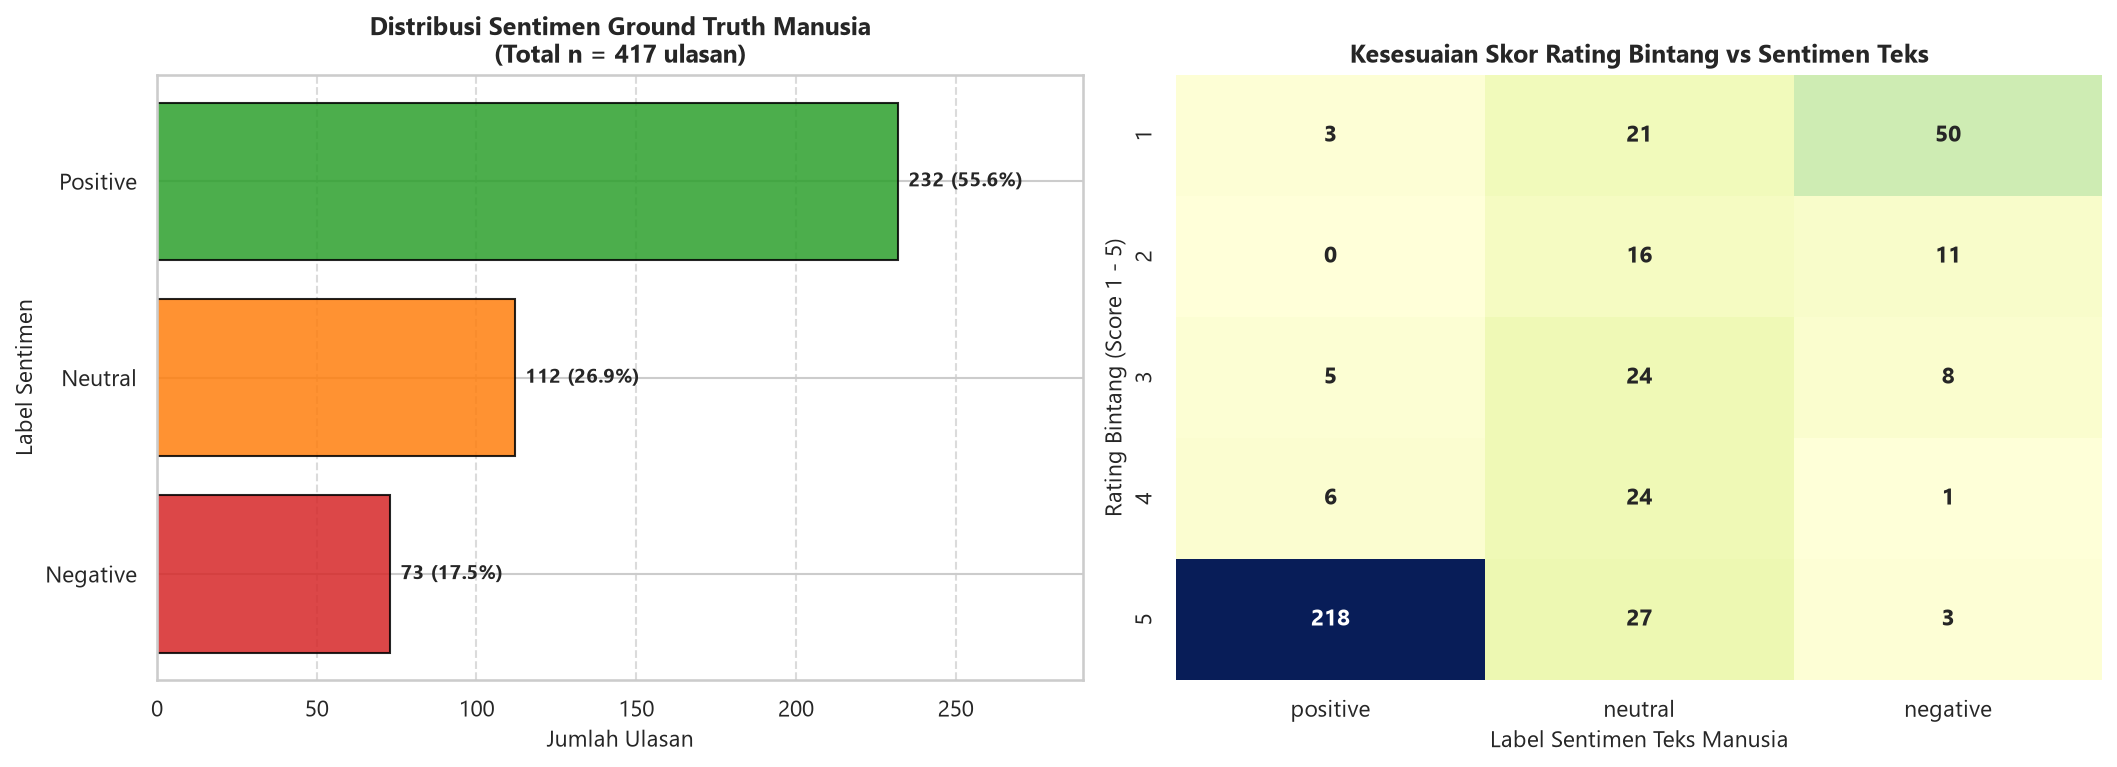

In [3]:
counts = gold['human_sentiment_label'].value_counts().reindex(['positive', 'neutral', 'negative'], fill_value=0)
pcts = (counts / len(gold) * 100).round(2)

dist_df = pd.DataFrame({
    'Label Sentimen Manusia': counts.index,
    'Jumlah Ulasan': counts.values,
    'Proporsi (%)': pcts.values
})
display(dist_df)

# Gabungkan dengan ulasan untuk membandingkan rating vs sentimen
merged = gold.merge(reviews[['review_id', 'score', 'rating_category']], on='review_id')
crosstab = pd.crosstab(merged['score'], merged['human_sentiment_label']).reindex(columns=['positive', 'neutral', 'negative'])

print('\nMatriks Silang: Skor Rating Bintang vs Label Sentimen Teks Manusia:')
display(crosstab)

# Visualisasi Distribusi dan Matriks Silang
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

# Subplot 1: Distribusi Sentimen Manusia
colors_sent = {'positive': '#2CA02C', 'neutral': '#FF7F0E', 'negative': '#D62728'}
bars = axes[0].barh(counts.index.str.capitalize(), counts.values,
                    color=[colors_sent[c] for c in counts.index], edgecolor='black', alpha=0.85)
axes[0].invert_yaxis()
axes[0].set_title(f'Distribusi Sentimen Ground Truth Manusia\n(Total n = {len(gold):,} ulasan)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Ulasan', fontsize=11)
axes[0].set_ylabel('Label Sentimen', fontsize=11)
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

for bar in bars:
    w = bar.get_width()
    pct = w / len(gold) * 100
    axes[0].annotate(f'{w:,} ({pct:.1f}%)',
                     xy=(w, bar.get_y() + bar.get_height() / 2),
                     xytext=(5, 0), textcoords="offset points",
                     ha='left', va='center', fontsize=9.5, fontweight='bold')
axes[0].set_xlim(0, max(counts.values) * 1.25)

# Subplot 2: Heatmap Rating Score vs Human Sentiment
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlGnBu', cbar=False, ax=axes[1],
            annot_kws={'size': 11, 'weight': 'bold'})
axes[1].set_title('Kesesuaian Skor Rating Bintang vs Sentimen Teks', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Label Sentimen Teks Manusia', fontsize=11)
axes[1].set_ylabel('Rating Bintang (Score 1 - 5)', fontsize=11)

fig_path_gold = FIG_DIR / 'goldset_distribution.png'
plt.savefig(fig_path_gold, dpi=200)
print(f'Figur tersimpan: {fig_path_gold}')
plt.show()


## 3. Contoh Kualitatif Divergensi Rating vs Sentimen Teks

Kasus-kasus di mana rating bintang berbeda dari muatan sentimen teks menegaskan mengapa pelabelan manual manusia sangat krusial dan tidak dapat digantikan oleh aturan skor rating sederhana:


In [4]:
merged_text = gold.merge(reviews[['review_id', 'score', 'rating_category']], on='review_id')

# Contoh: Rating bintang 5 tapi sentimen teks Netral (misal: pertanyaan teknis atau teks minimal)
sample_5_neu = merged_text[(merged_text['score'] == 5) & (merged_text['human_sentiment_label'] == 'neutral')].head(2)
print('=== CONTOH RATING BINTANG 5 DENGAN SENTIMEN TEKS NETRAL ===')
for _, r in sample_5_neu.iterrows():
    txt = r['review_text_clean'][:100]
    print(f"[{r['app_name']}] (Rating {r['score']}★, Teks: {r['human_sentiment_label']}): '{txt}'")

# Contoh: Rating bintang 3 tapi sentimen teks Positif atau Negatif
sample_3_div = merged_text[merged_text['score'] == 3].head(3)
print('\n=== CONTOH RATING BINTANG 3 DENGAN SENTIMEN TEKS SPESIFIK ===')
for _, r in sample_3_div.iterrows():
    txt = r['review_text_clean'][:100]
    print(f"[{r['app_name']}] (Rating {r['score']}★, Teks: {r['human_sentiment_label']}): '{txt}'")


=== CONTOH RATING BINTANG 5 DENGAN SENTIMEN TEKS NETRAL ===
[Zahir Attendance] (Rating 5★, Teks: neutral): 'aplikasi tidak kompatibel terus dihp saya,kenapa ya?'
[Zahir Attendance] (Rating 5★, Teks: neutral): 'Kok stelah photo malah lari ke splash screen trus ya'

=== CONTOH RATING BINTANG 3 DENGAN SENTIMEN TEKS SPESIFIK ===
[Zahir Attendance] (Rating 3★, Teks: negative): 'Sering gagal Absensi setelah Update dengan keterangan gagal terhubung ke server. Kadang bisa absensi'
[Zahir Certification] (Rating 3★, Teks: neutral): 'Ini kenapa ya mau login susah banget loading mulu, tolong diperbaiki lagi aplikasinya karena ini bua'
[Zahir Certification] (Rating 3★, Teks: neutral): 'Ini bayar apa gratis ya kak?'


## 4. Kesimpulan & Penegasan Metodologi

1. **Keabsahan Ground Truth**: Gold Set kanonikal 417 ulasan terverifikasi lengkap, unik, dan konsisten tanpa nilai hilang.
2. **Distribusi Kelas**: Kelas positif mendominasi (55.64%), diikuti netral (26.86%) dan negatif (17.51%), mencerminkan kurva kepuasan alami pengguna aplikasi Zahir.
3. **Pemisahan Konseptual yang Ketat**: Divergensi nyata antara rating numerik dan sentimen teks membuktikan keharusan membedakan variabel auxiliary rating dari label sentimen manusia murni.
4. **Kesiapan untuk Benchmarking**: Dataset ini menjadi fondasi evaluasi yang adil dan tidak bias bagi notebook pemodelan berikutnya (`04_sentiment_benchmark.ipynb`).
